# H&M Customer Segmentation — Phase 5
## Feature Selection & Feature-Set Experiments

## Mục tiêu

Phase 5 trả lời câu hỏi:

> **Trong các đặc trưng đã tạo ở Phase 4, đặc trưng nào thực sự đáng giữ cho Customer Segmentation?**

Ta không dùng một phương pháp duy nhất. Phase này kết hợp:

1. **Quality Filter** — coverage, missing, variance.
2. **Redundancy Analysis** — Spearman correlation.
3. **Filter Method** — ANOVA F-Test.
4. **Filter Method** — Mutual Information.
5. **Embedded Method** — Random Forest Feature Importance.
6. **Consensus Ranking** — tổng hợp thứ hạng từ nhiều phương pháp.
7. **Single-addition experiment** — RFM + từng extended feature.
8. **Forward feature-set experiment** — thêm dần feature theo ranking.
9. **Ablation experiment** — bỏ từng feature khỏi tập tốt để kiểm tra đóng góp.
10. **K-Means screening** trên cùng một sample và cùng `k` để đánh giá clustering utility.

### Nguyên tắc quan trọng

- Feature ranking **không dùng cluster label làm target**.
- Ta tạo target độc lập theo thời gian: `FuturePurchase`.
- Feature cho ranking chỉ được tính trong **observation window**.
- Future target chỉ lấy từ **future window**.
- Như vậy tránh circular reasoning và data leakage.
- Feature tốt cho `FuturePurchase` chưa chắc tốt cho clustering, nên phải kiểm chứng tiếp bằng K-Means screening.

Phase 5 chỉ tạo **candidate final feature set**.  
K-Means/GMM chính thức và tối ưu số cluster sẽ nằm ở Phase 6.

# 0. Thiết kế thời gian cho Feature Selection

Giả sử ngày cuối dataset là `MAX_DATE`.

Ta dùng:

\[
cutoff = MAX\_DATE - 30\ days
\]

### Observation window

Tất cả transaction:

\[
t \le cutoff
\]

Dùng để tính:

- R
- F
- M
- Interpurchase Time
- Diversity
- Channel behavior
- ...

### Future window

\[
cutoff < t \le MAX\_DATE
\]

Target:

\[
FuturePurchase =
\begin{cases}
1 & \text{nếu customer mua trong future window}\\
0 & \text{ngược lại}
\end{cases}
\]

Đây là target phục vụ **feature ranking**, không phải target của clustering.

## 1. Input / Output

Input:

```text
data/processed/
├── transactions_clean.parquet
├── customers_clean.parquet
└── articles_clean.parquet

data/features/
└── customer_features_master.parquet

reports/tables/phase4_features/
└── 11_phase5_candidate_feature_pool.csv
```

Output:

```text
reports/
├── figures/
│   └── phase5_feature_selection/
└── tables/
    └── phase5_feature_selection/

data/features/
├── phase5_observation_features.parquet
└── phase6_candidate_feature_set.csv
```

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_DIR = PROJECT_ROOT / "data" / "features"
PHASE4_TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "phase4_features"

FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "phase5_feature_selection"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "phase5_feature_selection"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

TX_PATH = PROCESSED_DIR / "transactions_clean.parquet"
CUSTOMERS_PATH = PROCESSED_DIR / "customers_clean.parquet"
ARTICLES_PATH = PROCESSED_DIR / "articles_clean.parquet"
MASTER_PATH = FEATURE_DIR / "customer_features_master.parquet"
OBS_PATH = FEATURE_DIR / "phase5_observation_features.parquet"
PHASE4_POOL_PATH = PHASE4_TABLE_DIR / "11_phase5_candidate_feature_pool.csv"

for p in [TX_PATH, CUSTOMERS_PATH, ARTICLES_PATH, MASTER_PATH]:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

..\data\processed\transactions_clean.parquet: OK
..\data\processed\customers_clean.parquet: OK
..\data\processed\articles_clean.parquet: OK
..\data\features\customer_features_master.parquet: OK


## 2. Configuration

Các giá trị dưới đây là **quy tắc screening**, không phải chân lý thống kê.

- `FUTURE_DAYS = 30`: khoảng thời gian dùng để tạo FuturePurchase.
- `HARD_MIN_COVERAGE_PCT = 20`: dưới mức này feature gần như không usable cho toàn population.
- `CAUTION_COVERAGE_PCT = 70`: feature dưới mức này vẫn được giữ để xem xét nhưng được gắn cờ.
- `REDUNDANCY_THRESHOLD = 0.90`: chỉ dùng để phát hiện cặp cực kỳ tương quan, **không tự động xóa**.
- Feature-set screening dùng sample cố định để kiểm soát chi phí tính toán.

In [2]:
RANDOM_STATE = 42

FUTURE_DAYS = 30

HARD_MIN_COVERAGE_PCT = 20.0
CAUTION_COVERAGE_PCT = 70.0
REDUNDANCY_THRESHOLD = 0.90

RANKING_MAX_CUSTOMERS = 250_000

SCREEN_SAMPLE_SIZE = 50_000
SILHOUETTE_SAMPLE_SIZE = 3_000

K_MIN = 2
K_MAX = 8

print("Configuration loaded.")


Configuration loaded.


# A. LOAD DATA

## 3. Load processed/master data

`customer_features_master.parquet` là bảng full-history từ Phase 4.  
Bảng này dùng cho **clustering screening**.

Feature ranking có FuturePurchase sẽ được xây lại từ transaction ở observation window để tránh leakage.

In [3]:
# Nếu chưa cài:
# %pip install duckdb pyarrow scikit-learn

import duckdb

con = duckdb.connect()
con.execute("SET max_memory = '2.5GB'")
con.execute("SET preserve_insertion_order = false")

articles = pd.read_parquet(ARTICLES_PATH)
master_full = pd.read_parquet(MASTER_PATH)

print("Master full:", master_full.shape)
display(master_full.head())

TX = f"read_parquet('{TX_PATH.as_posix()}')"
ART = f"read_parquet('{ARTICLES_PATH.as_posix()}')"


Master full: (1362281, 30)


,customer_id,first_purchase_date,last_purchase_date,recency_days,frequency_purchase_days,monetary_total_spend,item_frequency,interval_count,mean_interpurchase_days,median_interpurchase_days,std_interpurchase_days,min_interpurchase_days,max_interpurchase_days,avg_item_price,avg_spend_per_purchase_day,product_diversity,garment_group_diversity,colour_diversity,product_type_diversity,department_diversity,section_diversity,channel_diversity,dominant_channel_share,age,club_member_status,fashion_news_frequency,FN,Active,customer_tenure_days,items_per_purchase_day
0,8161cf725cd125586a9811433f957f5c6d47801f955517...,2018-09-26,2020-09-01,22,25,4.119034,117,24.0,29.416667,16.5,35.887404,1.0,164.0,0.035205,0.164761,96,18,21,26,39,17,2,0.897436,48.0,ACTIVE,NONE,NaN,NaN,706,4.680000
1,81d60d7dc77a8dcef9fc1ccfaf0011a58f20b97049b8ec...,2018-10-24,2020-07-11,74,12,0.997508,37,11.0,56.909091,45.0,50.106795,1.0,143.0,0.026960,0.083126,37,12,13,20,28,15,2,0.945946,53.0,ACTIVE,NONE,NaN,NaN,626,3.083333
2,8242e65d84adfde92b1170b176fabd1eb6676a15d04369...,2018-10-26,2018-10-26,698,1,0.025407,1,NaN,NaN,NaN,NaN,NaN,NaN,0.025407,0.025407,1,1,1,1,1,1,1,1.000000,49.0,ACTIVE,REGULARLY,1.0,1.0,0,1.000000
3,826a09c6c6c9dee397a3a22165fe2be8846fa2575eaf93...,2018-10-26,2019-03-15,558,4,0.223559,10,3.0,46.666667,42.0,21.385353,28.0,70.0,0.022356,0.055890,10,7,7,8,9,5,1,1.000000,73.0,ACTIVE,NONE,NaN,NaN,140,2.500000
4,83e4096636a357e0334f37567182e0f87350f725c5ba7e...,2018-09-21,2020-09-19,4,38,3.078797,114,37.0,19.702703,14.0,20.226310,1.0,88.0,0.027007,0.081021,111,18,20,35,46,20,2,0.561404,53.0,ACTIVE,NONE,NaN,NaN,729,3.000000


In [4]:
date_scope = con.execute(f'''
SELECT
    MIN(t_dat) AS min_date,
    MAX(t_dat) AS max_date,
    MAX(t_dat) - INTERVAL {FUTURE_DAYS} DAY AS cutoff_date
FROM {TX}
''').df()

display(date_scope)

MIN_DATE = pd.to_datetime(date_scope.loc[0, "min_date"])
MAX_DATE = pd.to_datetime(date_scope.loc[0, "max_date"])
CUTOFF_DATE = pd.to_datetime(date_scope.loc[0, "cutoff_date"])

print("Observation:", MIN_DATE.date(), "→", CUTOFF_DATE.date())
print("Future:", (CUTOFF_DATE + pd.Timedelta(days=1)).date(), "→", MAX_DATE.date())

date_scope.to_csv(TABLE_DIR / "01_feature_selection_time_split.csv", index=False)

,min_date,max_date,cutoff_date
0,2018-09-20,2020-09-22,2020-08-23


Observation: 2018-09-20 → 2020-08-23
Future: 2020-08-24 → 2020-09-22


# B. BUILD LEAKAGE-FREE OBSERVATION FEATURES

## 4. RFM trong observation window

Reference date cho Recency:

\[
reference\_date = cutoff + 1\ day
\]

In [5]:
obs_rfm = con.execute(f'''
WITH obs AS (
    SELECT *
    FROM {TX}
    WHERE t_dat <= DATE '{CUTOFF_DATE.date()}'
),
agg AS (
    SELECT
        customer_id,
        MIN(t_dat) AS first_purchase_date,
        MAX(t_dat) AS last_purchase_date,
        COUNT(DISTINCT t_dat) AS frequency_purchase_days,
        SUM(price) AS monetary_total_spend,
        COUNT(*) AS item_frequency
    FROM obs
    GROUP BY customer_id
)
SELECT
    customer_id,
    DATE_DIFF(
        'day',
        last_purchase_date,
        DATE '{CUTOFF_DATE.date()}' + INTERVAL 1 DAY
    ) AS recency_days,
    frequency_purchase_days,
    monetary_total_spend,
    item_frequency,
    DATE_DIFF('day', first_purchase_date, last_purchase_date) AS customer_tenure_days
FROM agg
''').df()

print("Observation RFM:", obs_rfm.shape)
display(obs_rfm.head())

Observation RFM: (1338029, 6)


,customer_id,recency_days,frequency_purchase_days,monetary_total_spend,item_frequency,customer_tenure_days
0,003ac6eff3ca20cbe4e14a106a5e28b7551616005de8f9...,30,53,3.615390,138,674
1,01ff82d2792db8d2f92caa1e934fd6a122117f99a47f50...,6,43,1.591373,74,698
2,02042b44255a14412b92f126844f9b33518e2cd598dc36...,222,5,1.301288,68,482
3,0218014619321c250395c5cb9bc9f5323745113f61f3a1...,14,38,7.296847,239,690
4,0257cce57bcfd65d958d44d09bd52c80b07b5a5aee9fc6...,21,46,7.607424,219,683


## 5. Temporal features trong observation window

In [6]:
obs_temporal = con.execute(f'''
WITH obs AS (
    SELECT DISTINCT customer_id, t_dat
    FROM {TX}
    WHERE t_dat <= DATE '{CUTOFF_DATE.date()}'
),
ordered AS (
    SELECT
        customer_id,
        t_dat,
        LAG(t_dat) OVER (
            PARTITION BY customer_id
            ORDER BY t_dat
        ) AS prev_date
    FROM obs
),
diffs AS (
    SELECT
        customer_id,
        DATE_DIFF('day', prev_date, t_dat) AS interval_days
    FROM ordered
    WHERE prev_date IS NOT NULL
)
SELECT
    customer_id,
    COUNT(*) AS interval_count,
    AVG(interval_days) AS mean_interpurchase_days,
    MEDIAN(interval_days) AS median_interpurchase_days,
    STDDEV_SAMP(interval_days) AS std_interpurchase_days
FROM diffs
GROUP BY customer_id
''').df()

display(obs_temporal.head())

,customer_id,interval_count,mean_interpurchase_days,median_interpurchase_days,std_interpurchase_days
0,66e03d5136f7a4cdcd82cde70becc04a7d42c46bb895e1...,22,30.181818,25.5,36.201337
1,66e1137a5cf34b7ae154a293cfb336120ce4af123dc45d...,1,132.000000,132.0,NaN
2,66e286a097d4df2d5af4353e4fdcf74e7281fa575515f5...,9,63.111111,66.0,36.788057
3,66e30b823e8b20b0a65490e4040928ac5b4530b7e197e6...,11,59.818182,54.0,61.025926
4,66e41abf33d59c6f8323b5d505aba0475e7d50419b7a92...,1,166.000000,166.0,NaN


## 6. Fashion-diversity features trong observation window

In [7]:
obs_fashion = con.execute(f'''
SELECT
    tx.customer_id,
    COUNT(DISTINCT tx.article_id) AS product_diversity,
    COUNT(DISTINCT a.garment_group_no) AS garment_group_diversity,
    COUNT(DISTINCT a.colour_group_code) AS colour_diversity,
    COUNT(DISTINCT a.product_type_no) AS product_type_diversity
FROM {TX} tx
JOIN {ART} a USING (article_id)
WHERE tx.t_dat <= DATE '{CUTOFF_DATE.date()}'
GROUP BY tx.customer_id
''').df()

display(obs_fashion.head())


,customer_id,product_diversity,garment_group_diversity,colour_diversity,product_type_diversity
0,62b04e1657cb577a84ddb9f649fbfabb3ff28ca88238cf...,26,10,12,10
1,62b40d3d30762973c69519150c30873f3ed2802b88fc24...,43,8,13,11
2,633a9b7e0ffaa0002c63e6df3c1759dd095f11fe035d14...,48,13,15,20
3,73831d6c7b05d5923ca64033722f105b75272d86adf82e...,30,8,13,10
4,75324df7a2339aab4ae95fee7bbfbf741198c6c8acaa99...,24,10,8,11


## 7. Spending/activity/channel features trong observation window

In [8]:
obs_extra = con.execute(f'''
WITH obs AS (
    SELECT *
    FROM {TX}
    WHERE t_dat <= DATE '{CUTOFF_DATE.date()}'
),
channel_counts AS (
    SELECT
        customer_id,
        sales_channel_id,
        COUNT(*) AS n
    FROM obs
    GROUP BY customer_id, sales_channel_id
),
channel_agg AS (
    SELECT
        customer_id,
        COUNT(*) AS channel_diversity,
        SUM(n) AS total_n,
        MAX(n) AS dominant_n
    FROM channel_counts
    GROUP BY customer_id
),
purchase_agg AS (
    SELECT
        customer_id,
        SUM(price) / COUNT(*) AS avg_item_price,
        SUM(price) / COUNT(DISTINCT t_dat) AS avg_spend_per_purchase_day,
        COUNT(*) * 1.0 / COUNT(DISTINCT t_dat) AS items_per_purchase_day
    FROM obs
    GROUP BY customer_id
)
SELECT
    p.customer_id,
    p.avg_item_price,
    p.avg_spend_per_purchase_day,
    p.items_per_purchase_day,
    c.channel_diversity,
    c.dominant_n * 1.0 / c.total_n AS dominant_channel_share
FROM purchase_agg p
LEFT JOIN channel_agg c USING (customer_id)
''').df()

display(obs_extra.head())

,customer_id,avg_item_price,avg_spend_per_purchase_day,items_per_purchase_day,channel_diversity,dominant_channel_share
0,0fff43dd7477ebecdbbe41c6c98f4755bf7a274a8f419a...,0.052898,0.188923,3.571429,1,1.000000
1,1e93a1eb9f7d4d4350ac7de30110b02a488dbf74594b99...,0.040177,0.070309,1.750000,1,1.000000
2,3de2d35f96f7d6f1114c78bd439c3b6465668007f56ca0...,0.026172,0.049560,1.893617,2,0.617978
3,5203a4ca7f06cff0481ac7c2064a71fa3494487860a4b0...,0.029288,0.484875,16.555556,2,0.996644
4,5c8107292cda0284474995114169fc159e60bd01ab2aeb...,0.016362,0.087536,5.350000,2,0.943925


## 8. FuturePurchase target

Customer universe = khách đã xuất hiện trong observation window.

Target bằng 1 nếu customer có ít nhất một transaction trong 30 ngày tương lai.

,customer_id,future_purchase
0,3578f9a664e4d44616b66846f670c823617e550cf84b33...,1
1,3729304f7d3c93a1e5a96b7ea72f2cf448aac545ac6a5d...,0
2,382232fd3448e07ab026d1517686d8e5a0b8370155647d...,0
3,3e1b2041f08ded3370be03fa3526fe1e6bf5c57c3eb85d...,0
4,3e2f53a39d8a26b3febf02b7be295195cf3dc47fcfcb4f...,0


,future_purchase,customers,pct
0,0,1116336,83.431376
1,1,221693,16.568624


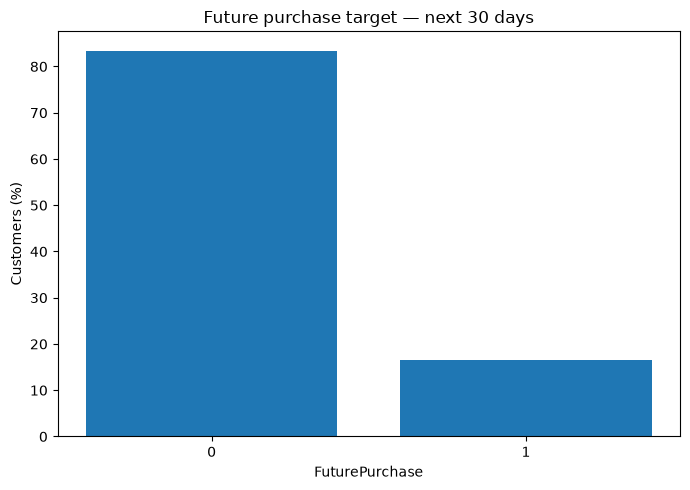

In [9]:
future_target = con.execute(f'''
WITH obs_customers AS (
    SELECT DISTINCT customer_id
    FROM {TX}
    WHERE t_dat <= DATE '{CUTOFF_DATE.date()}'
),
future_customers AS (
    SELECT DISTINCT customer_id
    FROM {TX}
    WHERE
        t_dat > DATE '{CUTOFF_DATE.date()}'
        AND t_dat <= DATE '{MAX_DATE.date()}'
)
SELECT
    o.customer_id,
    CASE WHEN f.customer_id IS NOT NULL THEN 1 ELSE 0 END AS future_purchase
FROM obs_customers o
LEFT JOIN future_customers f USING (customer_id)
''').df()

display(future_target.head())

target_balance = (
    future_target["future_purchase"]
    .value_counts()
    .sort_index()
    .rename_axis("future_purchase")
    .reset_index(name="customers")
)
target_balance["pct"] = target_balance["customers"] / len(future_target) * 100

display(target_balance)
target_balance.to_csv(TABLE_DIR / "02_future_purchase_target_balance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(target_balance["future_purchase"].astype(str), target_balance["pct"])
ax.set_xlabel("FuturePurchase")
ax.set_ylabel("Customers (%)")
ax.set_title(f"Future purchase target — next {FUTURE_DAYS} days")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_future_purchase_target_balance.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Observation feature table

Join tất cả feature với target.

Không dùng thông tin phát sinh trong future window để tính X.

In [ ]:
if 'OBS_PATH' not in locals():
    OBS_PATH = FEATURE_DIR / 'phase5_observation_features.parquet'

# Ghép nối các đặc trưng quan sát
if 'obs_rfm' in locals() and 'obs_temporal' in locals() and 'obs_fashion' in locals():
    obs_features = (
        obs_rfm
        .merge(obs_temporal, on="customer_id", how="left")
        .merge(obs_fashion, on="customer_id", how="left")
        .merge(obs_extra, on="customer_id", how="left")
        .merge(future_target, on="customer_id", how="left")
    )
    assert obs_features["customer_id"].duplicated().sum() == 0
    assert obs_features["future_purchase"].isna().sum() == 0
    obs_features.to_parquet(OBS_PATH, index=False)
    print("Saved new observation feature table:", OBS_PATH)
elif OBS_PATH.exists():
    obs_features = pd.read_parquet(OBS_PATH)
    print("Loaded existing observation features:", obs_features.shape)

print("Observation feature table:", obs_features.shape)
display(obs_features.head())

# C. QUALITY FILTER

## 10. Candidate pool

RFM core luôn được giữ làm baseline.

Extended features phải qua quality screening trước khi ranking.

In [ ]:
CORE_FEATURES = [
    "recency_days",
    "frequency_purchase_days",
    "monetary_total_spend"
]

DEFAULT_EXTENDED = [
    "mean_interpurchase_days",
    "std_interpurchase_days",
    "avg_item_price",
    "avg_spend_per_purchase_day",
    "product_diversity",
    "product_type_diversity",
    "garment_group_diversity",
    "colour_diversity",
    "dominant_channel_share",
    "items_per_purchase_day"
]

if PHASE4_POOL_PATH.exists():
    phase4_pool = pd.read_csv(PHASE4_POOL_PATH)
    phase4_candidate_names = phase4_pool["feature"].tolist()
    candidate_features = [
        f for f in phase4_candidate_names
        if f in obs_features.columns
    ]
else:
    candidate_features = [
        f for f in CORE_FEATURES + DEFAULT_EXTENDED
        if f in obs_features.columns
    ]

# Guarantee baseline.
for f in CORE_FEATURES:
    if f in obs_features.columns and f not in candidate_features:
        candidate_features.insert(0, f)

print("Candidate features:")
print(candidate_features)

In [ ]:
quality_rows = []

for f in candidate_features:
    s = pd.to_numeric(obs_features[f], errors="coerce")
    non_null = s.dropna()

    coverage = s.notna().mean() * 100
    std = non_null.std() if len(non_null) else np.nan
    n_unique = non_null.nunique()

    if f in CORE_FEATURES:
        status = "CORE_KEEP"
    elif coverage < HARD_MIN_COVERAGE_PCT or n_unique <= 1 or (pd.notna(std) and std == 0):
        status = "DROP_HARD"
    elif coverage < CAUTION_COVERAGE_PCT:
        status = "CAUTION"
    else:
        status = "OK"

    quality_rows.append({
        "feature": f,
        "role": "CORE" if f in CORE_FEATURES else "EXTENDED",
        "coverage_pct": coverage,
        "missing_pct": 100 - coverage,
        "n_unique": n_unique,
        "std": std,
        "skewness": non_null.skew() if len(non_null) > 2 else np.nan,
        "quality_status": status
    })

quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv(TABLE_DIR / "03_feature_quality_filter.csv", index=False)

eligible_features = quality.loc[
    quality["quality_status"] != "DROP_HARD",
    "feature"
].tolist()

eligible_extended = [
    f for f in eligible_features
    if f not in CORE_FEATURES
]

print("Eligible:", eligible_features)

In [ ]:
plot_quality = quality.sort_values("coverage_pct")

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_quality) * 0.35)))
ax.barh(plot_quality["feature"], plot_quality["coverage_pct"])
ax.set_xlabel("Coverage (%)")
ax.set_title("Feature coverage — observation window")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_feature_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

# D. REDUNDANCY ANALYSIS

## 11. Spearman correlation

`|rho| >= 0.90` được gắn cờ là redundancy mạnh.

**Không tự động xóa** ở bước này.  
Ta cần kết hợp correlation với ranking, business meaning và clustering experiment.

In [ ]:
corr = obs_features[eligible_features].corr(method="spearman")

display(corr.round(3))
corr.to_csv(TABLE_DIR / "04_spearman_correlation.csv")

pairs = []
for i, a in enumerate(corr.columns):
    for j in range(i + 1, len(corr.columns)):
        b = corr.columns[j]
        rho = corr.loc[a, b]
        if abs(rho) >= REDUNDANCY_THRESHOLD:
            pairs.append({
                "feature_a": a,
                "feature_b": b,
                "spearman_rho": rho,
                "abs_rho": abs(rho)
            })

redundant_pairs = pd.DataFrame(pairs).sort_values(
    "abs_rho", ascending=False
) if pairs else pd.DataFrame(
    columns=["feature_a", "feature_b", "spearman_rho", "abs_rho"]
)

display(redundant_pairs)
redundant_pairs.to_csv(TABLE_DIR / "05_high_redundancy_pairs.csv", index=False)

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Spearman correlation — eligible features")
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_feature_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

# E. FILTER + EMBEDDED FEATURE RANKING

## 12. Sampling và preprocessing

Vì H&M có rất nhiều customer, feature ranking dùng một **stratified sample cố định** nếu population vượt quá `RANKING_MAX_CUSTOMERS`.

Preprocessing cho ranking:

1. Median imputation trên training set.
2. StandardScaler cho ANOVA / Mutual Information.
3. Random Forest dùng dữ liệu imputed (scale không bắt buộc).

Không dùng test set để fit ranking.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

rank_df = obs_features[
    ["customer_id", "future_purchase"] + eligible_features
].copy()

# Ensure numeric.
for f in eligible_features:
    rank_df[f] = pd.to_numeric(rank_df[f], errors="coerce")

if len(rank_df) > RANKING_MAX_CUSTOMERS:
    rank_sample, _ = train_test_split(
        rank_df,
        train_size=RANKING_MAX_CUSTOMERS,
        stratify=rank_df["future_purchase"],
        random_state=RANDOM_STATE
    )
else:
    rank_sample = rank_df.copy()

train_df, test_df = train_test_split(
    rank_sample,
    test_size=0.20,
    stratify=rank_sample["future_purchase"],
    random_state=RANDOM_STATE
)

X_train_raw = train_df[eligible_features]
X_test_raw = test_df[eligible_features]

y_train = train_df["future_purchase"].astype(int)
y_test = test_df["future_purchase"].astype(int)

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train_raw)
X_test_imp = imputer.transform(X_test_raw)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Ranking sample:", len(rank_sample))
print("Train:", len(train_df), "Test:", len(test_df))
print("Positive rate train:", y_train.mean())
print("Positive rate test:", y_test.mean())

## 13. Filter Method — ANOVA F-Test

ANOVA trả lời:

> Feature nào có sự khác biệt về trung bình đáng kể giữa nhóm có/không có FuturePurchase?

ANOVA chỉ là một góc nhìn; nó không bắt tốt mọi quan hệ phi tuyến.

In [ ]:
anova_selector = SelectKBest(score_func=f_classif, k="all")
anova_selector.fit(X_train_scaled, y_train)

anova_result = pd.DataFrame({
    "feature": eligible_features,
    "anova_f_score": anova_selector.scores_,
    "anova_p_value": anova_selector.pvalues_
}).sort_values("anova_f_score", ascending=False)

anova_result["anova_rank"] = (
    anova_result["anova_f_score"]
    .rank(method="min", ascending=False)
)

display(anova_result)
anova_result.to_csv(TABLE_DIR / "06_anova_feature_ranking.csv", index=False)

In [ ]:
plot_df = anova_result.head(15).sort_values("anova_f_score")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["feature"], plot_df["anova_f_score"])
ax.set_xlabel("ANOVA F-score")
ax.set_title("Filter Method — ANOVA feature ranking")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_anova_feature_ranking.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Filter Method — Mutual Information

Mutual Information có thể phát hiện quan hệ phi tuyến mà ANOVA có thể bỏ sót.

In [ ]:
mi_selector = SelectKBest(
    score_func=lambda X, y: mutual_info_classif(
        X, y, random_state=RANDOM_STATE
    ),
    k="all"
)
mi_selector.fit(X_train_scaled, y_train)

mi_result = pd.DataFrame({
    "feature": eligible_features,
    "mutual_information": mi_selector.scores_
}).sort_values("mutual_information", ascending=False)

mi_result["mi_rank"] = (
    mi_result["mutual_information"]
    .rank(method="min", ascending=False)
)

display(mi_result)
mi_result.to_csv(TABLE_DIR / "07_mutual_information_ranking.csv", index=False)

In [ ]:
plot_df = mi_result.head(15).sort_values("mutual_information")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["feature"], plot_df["mutual_information"])
ax.set_xlabel("Mutual Information")
ax.set_title("Filter Method — Mutual Information ranking")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_mutual_information_ranking.png", dpi=160, bbox_inches="tight")
plt.show()

## 15. Embedded Method — Random Forest Feature Importance

Random Forest dùng `FuturePurchase` làm target độc lập.

Ta đồng thời kiểm tra ROC-AUC và Average Precision trên test set để xác nhận ranking model có tín hiệu thực sự.  
Mục tiêu **không phải xây classifier production**.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_imp, y_train)

test_prob = rf.predict_proba(X_test_imp)[:, 1]

rf_auc = roc_auc_score(y_test, test_prob)
rf_ap = average_precision_score(y_test, test_prob)

rf_validation = pd.DataFrame({
    "metric": ["ROC_AUC", "Average_Precision"],
    "value": [rf_auc, rf_ap]
})
display(rf_validation)
rf_validation.to_csv(TABLE_DIR / "08_random_forest_validation.csv", index=False)

rf_result = pd.DataFrame({
    "feature": eligible_features,
    "rf_importance": rf.feature_importances_
}).sort_values("rf_importance", ascending=False)

rf_result["rf_rank"] = (
    rf_result["rf_importance"]
    .rank(method="min", ascending=False)
)

display(rf_result)
rf_result.to_csv(TABLE_DIR / "09_random_forest_importance.csv", index=False)

In [ ]:
plot_df = rf_result.head(15).sort_values("rf_importance")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["feature"], plot_df["rf_importance"])
ax.set_xlabel("Random Forest importance")
ax.set_title("Embedded Method — Random Forest feature importance")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_random_forest_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. Optional — Chi-Squared

Chi-Squared **không nằm trong pipeline chính** vì ANOVA + MI đã cung cấp hai Filter perspectives.

Nếu giảng viên yêu cầu chạy `chi2`, phải bảo đảm dữ liệu không âm, ví dụ dùng MinMaxScaler.  
Cell dưới mặc định tắt.

In [ ]:
RUN_OPTIONAL_CHI2 = False

if RUN_OPTIONAL_CHI2:
    from sklearn.preprocessing import MinMaxScaler
    from sklearn.feature_selection import chi2

    mm = MinMaxScaler()
    X_train_nonnegative = mm.fit_transform(X_train_imp)

    chi_selector = SelectKBest(score_func=chi2, k="all")
    chi_selector.fit(X_train_nonnegative, y_train)

    chi_result = pd.DataFrame({
        "feature": eligible_features,
        "chi2_score": chi_selector.scores_,
        "chi2_p_value": chi_selector.pvalues_
    }).sort_values("chi2_score", ascending=False)

    display(chi_result)
    chi_result.to_csv(TABLE_DIR / "optional_chi2_ranking.csv", index=False)
else:
    print("Optional chi2 skipped.")

# F. CONSENSUS RANKING

## 17. Kết hợp ANOVA + MI + Random Forest

Ta dùng:

\[
ConsensusRank =
rac{Rank_{ANOVA}+Rank_{MI}+Rank_{RF}}{3}
\]

Rank càng thấp càng tốt.

Consensus ranking giúp tránh phụ thuộc vào duy nhất một phương pháp.

In [ ]:
consensus = (
    anova_result[["feature", "anova_f_score", "anova_p_value", "anova_rank"]]
    .merge(
        mi_result[["feature", "mutual_information", "mi_rank"]],
        on="feature"
    )
    .merge(
        rf_result[["feature", "rf_importance", "rf_rank"]],
        on="feature"
    )
    .merge(
        quality[[
            "feature",
            "coverage_pct",
            "quality_status"
        ]],
        on="feature",
        how="left"
    )
)

consensus["consensus_rank"] = consensus[
    ["anova_rank", "mi_rank", "rf_rank"]
].mean(axis=1)

consensus["is_core_rfm"] = consensus["feature"].isin(CORE_FEATURES)

consensus = consensus.sort_values(
    ["consensus_rank", "feature"]
).reset_index(drop=True)

display(consensus)
consensus.to_csv(TABLE_DIR / "10_consensus_feature_ranking.csv", index=False)

ranked_extended = consensus.loc[
    ~consensus["is_core_rfm"],
    "feature"
].tolist()

print("Extended ranking:")
for i, f in enumerate(ranked_extended, 1):
    print(i, f)

In [ ]:
plot_df = (
    consensus
    .sort_values("consensus_rank", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["feature"], plot_df["consensus_rank"])
ax.set_xlabel("Average rank (lower is better)")
ax.set_title("Consensus feature ranking")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_consensus_feature_ranking.png", dpi=160, bbox_inches="tight")
plt.show()

# G. K-MEANS SCREENING SETUP

## 18. Vì sao Phase 5 đã dùng K-Means?

ANOVA/MI/RF chỉ đánh giá feature theo `FuturePurchase`.

Nhưng mục tiêu cuối cùng là **clustering**, nên cần thêm bằng chứng:

> Khi feature được đưa vào clustering, cluster có tách tốt hơn không?

Để so sánh công bằng giữa feature sets:

1. Dùng **cùng customer sample**.
2. Dùng cùng preprocessing rule.
3. Xác định một `SCREEN_K` từ **RFM baseline**.
4. Tất cả feature-set experiments ở Phase 5 dùng cùng `SCREEN_K`.

Như vậy khi metric thay đổi, nguyên nhân chính là **feature set**, không phải do ta đổi `k`.

Phase 6 sẽ tối ưu `k` lại trên final feature set.

In [ ]:
import gc
# Thu dọn bộ nhớ ranking và observation data trước khi bước vào clustering
if 'obs_features' in locals():
    del obs_features
if 'rank_df' in locals():
    del rank_df
if 'X_train' in locals():
    del X_train, X_test, y_train, y_test
if 'rf' in locals():
    del rf
gc.collect()

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

master_full = pd.read_parquet(MASTER_PATH)
if len(master_full) > SCREEN_SAMPLE_SIZE:
    screen_sample = master_full.sample(
        n=SCREEN_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).copy()
else:
    screen_sample = master_full.copy()
del master_full
gc.collect()

print("Screen sample:", screen_sample.shape)


## 19. Preprocessing cho clustering screening

Rule:

- numeric only;
- median imputation;
- nếu feature không âm và skewness > 1 → `log1p`;
- StandardScaler.

Transform rule được ghi lại để báo cáo.

Đây là **screening preprocessing**, Phase 6 sẽ kiểm tra transformation kỹ hơn trước final model.

In [ ]:
def prepare_cluster_matrix(df, features):
    X = df[features].copy()

    transform_log = []
    transform_rows = []

    for f in features:
        s = pd.to_numeric(X[f], errors="coerce")
        non_null = s.dropna()

        apply_log = (
            len(non_null) > 2
            and non_null.min() >= 0
            and abs(non_null.skew()) > 1
        )

        if apply_log:
            X[f] = np.log1p(s)
            transform_name = "log1p"
        else:
            X[f] = s
            transform_name = "identity"

        transform_rows.append({
            "feature": f,
            "transform": transform_name,
            "raw_skewness": non_null.skew() if len(non_null) > 2 else np.nan
        })

    imputer = SimpleImputer(strategy="median")
    X_imp = imputer.fit_transform(X)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imp)

    return X_scaled, pd.DataFrame(transform_rows)

# H. BASELINE K SELECTION FOR SCREENING

## 20. Chọn SCREEN_K từ RFM baseline

Chạy:

\[
k=2,\ldots,8
\]

trên RFM baseline.

Metric:

- Silhouette ↑
- Davies-Bouldin ↓
- Calinski-Harabasz ↑

`SCREEN_K` mặc định lấy k có Silhouette cao nhất.  
Đây chỉ là k dùng để **so feature set trong Phase 5**.

In [ ]:
X_rfm, rfm_transform = prepare_cluster_matrix(
    screen_sample,
    CORE_FEATURES
)

rfm_transform.to_csv(
    TABLE_DIR / "11_rfm_screening_transform.csv",
    index=False
)

baseline_k_rows = []

sil_n = min(SILHOUETTE_SAMPLE_SIZE, len(screen_sample))

for k in range(K_MIN, K_MAX + 1):
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = km.fit_predict(X_rfm)

    sil = silhouette_score(
        X_rfm,
        labels,
        sample_size=sil_n,
        random_state=RANDOM_STATE
    )

    dbi = davies_bouldin_score(X_rfm, labels)
    ch = calinski_harabasz_score(X_rfm, labels)

    baseline_k_rows.append({
        "k": k,
        "silhouette": sil,
        "davies_bouldin": dbi,
        "calinski_harabasz": ch
    })

baseline_k = pd.DataFrame(baseline_k_rows)
display(baseline_k)
baseline_k.to_csv(TABLE_DIR / "12_rfm_baseline_k_screening.csv", index=False)

SCREEN_K = int(
    baseline_k.sort_values(
        ["silhouette", "davies_bouldin"],
        ascending=[False, True]
    ).iloc[0]["k"]
)

print("SCREEN_K =", SCREEN_K)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(baseline_k["k"], baseline_k["silhouette"], marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette")
ax.set_title("RFM baseline — Silhouette by k")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_rfm_silhouette_by_k.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(baseline_k["k"], baseline_k["davies_bouldin"], marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Davies-Bouldin")
ax.set_title("RFM baseline — Davies-Bouldin by k")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_rfm_dbi_by_k.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(baseline_k["k"], baseline_k["calinski_harabasz"], marker="o")
ax.set_xlabel("k")
ax.set_ylabel("Calinski-Harabasz")
ax.set_title("RFM baseline — Calinski-Harabasz by k")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_rfm_ch_by_k.png", dpi=160, bbox_inches="tight")
plt.show()

# I. FEATURE-SET EVALUATION FUNCTION

## 21. Evaluation rule

Mỗi feature set chạy cùng:

- customer sample;
- `SCREEN_K`;
- preprocessing rule;
- random state.

Sau đó tính 3 metrics.

In [ ]:
def evaluate_feature_set(name, features):
    features = list(dict.fromkeys(features))

    X, transform_log = prepare_cluster_matrix(
        screen_sample,
        features
    )

    km = KMeans(
        n_clusters=SCREEN_K,
        n_init=10,
        random_state=RANDOM_STATE
    )
    labels = km.fit_predict(X)

    sil_n = min(SILHOUETTE_SAMPLE_SIZE, len(screen_sample))

    result = {
        "experiment": name,
        "n_features": len(features),
        "features": " | ".join(features),
        "silhouette": silhouette_score(
            X,
            labels,
            sample_size=sil_n,
            random_state=RANDOM_STATE
        ),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "min_cluster_pct": (
            pd.Series(labels).value_counts(normalize=True).min() * 100
        ),
        "max_cluster_pct": (
            pd.Series(labels).value_counts(normalize=True).max() * 100
        )
    }

    return result, transform_log

# J. SINGLE-ADDITION EXPERIMENTS

## 22. RFM + từng extended feature

Đây là cách kiểm tra trực tiếp:

> Khi chỉ thêm một feature vào RFM baseline, clustering thay đổi như thế nào?

Ta không cần brute-force mọi tổ hợp.

In [ ]:
single_results = []

base_result, _ = evaluate_feature_set("RFM_BASELINE", CORE_FEATURES)
single_results.append(base_result)

for f in ranked_extended:
    result, _ = evaluate_feature_set(
        f"RFM_PLUS_{f}",
        CORE_FEATURES + [f]
    )
    single_results.append(result)

single_df = pd.DataFrame(single_results)

# Metric deltas relative to baseline.
base_sil = single_df.loc[
    single_df["experiment"] == "RFM_BASELINE",
    "silhouette"
].iloc[0]

base_dbi = single_df.loc[
    single_df["experiment"] == "RFM_BASELINE",
    "davies_bouldin"
].iloc[0]

base_ch = single_df.loc[
    single_df["experiment"] == "RFM_BASELINE",
    "calinski_harabasz"
].iloc[0]

single_df["delta_silhouette"] = single_df["silhouette"] - base_sil
single_df["delta_dbi"] = single_df["davies_bouldin"] - base_dbi
single_df["delta_ch"] = single_df["calinski_harabasz"] - base_ch

display(single_df.sort_values("silhouette", ascending=False))
single_df.to_csv(TABLE_DIR / "13_single_addition_experiments.csv", index=False)

In [ ]:
plot_df = single_df.sort_values("silhouette")

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["silhouette"])
ax.set_xlabel("Silhouette")
ax.set_title(f"Single-addition experiments — fixed k={SCREEN_K}")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_single_addition_silhouette.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
plot_df = single_df.sort_values("davies_bouldin", ascending=False)

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["davies_bouldin"])
ax.set_xlabel("Davies-Bouldin (lower is better)")
ax.set_title(f"Single-addition experiments — fixed k={SCREEN_K}")
fig.tight_layout()
fig.savefig(FIG_DIR / "12_single_addition_dbi.png", dpi=160, bbox_inches="tight")
plt.show()

# K. FORWARD FEATURE-SELECTION EXPERIMENT

## 23. Thêm dần feature theo consensus ranking

Bắt đầu:

\[
RFM
\]

Sau đó:

\[
RFM + Top1
\]

\[
RFM + Top1 + Top2
\]

...

Cách này giảm số experiment đáng kể so với thử toàn bộ \(2^p-1\) tổ hợp.

In [ ]:
forward_results = []
current = CORE_FEATURES.copy()

result, _ = evaluate_feature_set(
    "FORWARD_0_RFM",
    current
)
forward_results.append(result)

for i, f in enumerate(ranked_extended, 1):
    current = current + [f]

    result, _ = evaluate_feature_set(
        f"FORWARD_{i}",
        current
    )
    forward_results.append(result)

forward_df = pd.DataFrame(forward_results)
display(forward_df)

## 24. Composite metric rank

Không chọn feature set chỉ bằng Silhouette.

Ta tạo:

- rank Silhouette: cao tốt;
- rank DBI: thấp tốt;
- rank CH: cao tốt;

và:

\[
CompositeRank =
rac{Rank_{Sil}+Rank_{DBI}+Rank_{CH}}{3}
\]

CompositeRank thấp hơn tốt hơn.

`min_cluster_pct` và `max_cluster_pct` vẫn được giữ để phát hiện cluster quá mất cân bằng.

In [ ]:
def add_composite_rank(df):
    out = df.copy()

    out["rank_silhouette"] = out["silhouette"].rank(
        method="min",
        ascending=False
    )
    out["rank_dbi"] = out["davies_bouldin"].rank(
        method="min",
        ascending=True
    )
    out["rank_ch"] = out["calinski_harabasz"].rank(
        method="min",
        ascending=False
    )

    out["composite_rank"] = out[
        ["rank_silhouette", "rank_dbi", "rank_ch"]
    ].mean(axis=1)

    return out.sort_values(
        ["composite_rank", "silhouette"],
        ascending=[True, False]
    )

forward_ranked = add_composite_rank(forward_df)

display(forward_ranked)
forward_ranked.to_csv(TABLE_DIR / "14_forward_feature_experiments.csv", index=False)

best_forward = forward_ranked.iloc[0]
BEST_FORWARD_FEATURES = best_forward["features"].split(" | ")

print("Best forward screening set:")
print(BEST_FORWARD_FEATURES)

In [ ]:
plot_df = forward_ranked.sort_values("composite_rank", ascending=False)

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["composite_rank"])
ax.set_xlabel("Composite rank (lower is better)")
ax.set_title("Forward feature-set comparison")
fig.tight_layout()
fig.savefig(FIG_DIR / "13_forward_composite_rank.png", dpi=160, bbox_inches="tight")
plt.show()

# L. TOP-K CANDIDATE SETS

## 25. RFM + Top-N extended features

Ngoài forward path đầy đủ, ta lưu các mốc dễ trình bày trong báo cáo:

- RFM
- RFM + Top1
- RFM + Top2
- RFM + Top3
- RFM + Top5
- All eligible

In [ ]:
topn_options = [1, 2, 3, 5]
topk_rows = []

base_result, _ = evaluate_feature_set(
    "TOPK_RFM",
    CORE_FEATURES
)
topk_rows.append(base_result)

for n in topn_options:
    chosen = ranked_extended[:min(n, len(ranked_extended))]

    if not chosen:
        continue

    result, _ = evaluate_feature_set(
        f"RFM_TOP_{len(chosen)}_EXTENDED",
        CORE_FEATURES + chosen
    )
    topk_rows.append(result)

all_result, _ = evaluate_feature_set(
    "RFM_ALL_ELIGIBLE_EXTENDED",
    CORE_FEATURES + ranked_extended
)
topk_rows.append(all_result)

topk_df = add_composite_rank(pd.DataFrame(topk_rows))
display(topk_df)
topk_df.to_csv(TABLE_DIR / "15_topk_feature_set_comparison.csv", index=False)

# M. ABLATION EXPERIMENT

## 26. Bỏ từng extended feature khỏi tập tốt

Nếu tập tốt nhất là:

\[
RFM + A + B + C
\]

ta thử:

- bỏ A;
- bỏ B;
- bỏ C.

Nếu bỏ một feature mà metric tốt hơn hoặc gần như không đổi, feature đó có thể không cần thiết.

In [ ]:
ablation_rows = []

# Include original best set.
original_result, _ = evaluate_feature_set(
    "ABLATION_ORIGINAL",
    BEST_FORWARD_FEATURES
)
ablation_rows.append(original_result)

for f in BEST_FORWARD_FEATURES:
    # Never ablate RFM core in this project design.
    if f in CORE_FEATURES:
        continue

    reduced = [
        x for x in BEST_FORWARD_FEATURES
        if x != f
    ]

    result, _ = evaluate_feature_set(
        f"REMOVE_{f}",
        reduced
    )
    ablation_rows.append(result)

ablation_df = add_composite_rank(pd.DataFrame(ablation_rows))
display(ablation_df)
ablation_df.to_csv(TABLE_DIR / "16_ablation_experiments.csv", index=False)

In [ ]:
plot_df = ablation_df.sort_values("composite_rank", ascending=False)

fig, ax = plt.subplots(figsize=(10, max(5, len(plot_df) * 0.4)))
ax.barh(plot_df["experiment"], plot_df["composite_rank"])
ax.set_xlabel("Composite rank (lower is better)")
ax.set_title("Ablation experiment")
fig.tight_layout()
fig.savefig(FIG_DIR / "14_ablation_composite_rank.png", dpi=160, bbox_inches="tight")
plt.show()

# N. PHASE 6 CANDIDATE FEATURE SET

## 27. Recommendation rule

Ta chưa gọi đây là **final feature set**.

Notebook chọn candidate cho Phase 6 từ:
- best forward set;
- các ablation alternatives.

Tập có CompositeRank tốt nhất được xuất dưới nhãn:

> `PHASE6_CANDIDATE`

Phase 6 phải kiểm chứng lại:
- transformation;
- optimal k;
- stability;
- K-Means vs GMM;
- interpretability.

In [ ]:
phase6_candidates = pd.concat([
    forward_ranked.assign(source="FORWARD"),
    ablation_df.assign(source="ABLATION")
], ignore_index=True)

phase6_candidates = add_composite_rank(
    phase6_candidates.drop(
        columns=[
            c for c in [
                "rank_silhouette",
                "rank_dbi",
                "rank_ch",
                "composite_rank"
            ]
            if c in phase6_candidates.columns
        ]
    )
)

recommended = phase6_candidates.iloc[0]
recommended_features = recommended["features"].split(" | ")

phase6_feature_set = pd.DataFrame({
    "feature": recommended_features,
    "role": [
        "RFM_CORE" if f in CORE_FEATURES else "EXTENDED_SELECTED"
        for f in recommended_features
    ]
})

display(phase6_feature_set)

PHASE6_SET_PATH = FEATURE_DIR / "phase6_candidate_feature_set.csv"
phase6_feature_set.to_csv(PHASE6_SET_PATH, index=False)

print("Saved:", PHASE6_SET_PATH)
print("Phase 6 candidate:", recommended_features)

# O. FEATURE-SELECTION DECISION TABLE

## 28. Tổng hợp bằng chứng cho từng feature

Bảng này là một trong những bảng quan trọng nhất để đưa vào báo cáo.

Nó gom:

- coverage;
- quality status;
- ANOVA rank;
- MI rank;
- RF rank;
- consensus rank;
- single-addition clustering delta;
- selected/not selected for Phase 6.

In [ ]:
single_feature_map = {}

for _, row in single_df.iterrows():
    if row["experiment"] == "RFM_BASELINE":
        continue

    prefix = "RFM_PLUS_"
    if row["experiment"].startswith(prefix):
        f = row["experiment"][len(prefix):]
        single_feature_map[f] = {
            "single_delta_silhouette": row["delta_silhouette"],
            "single_delta_dbi": row["delta_dbi"],
            "single_delta_ch": row["delta_ch"]
        }

decision = consensus.copy()

decision["single_delta_silhouette"] = decision["feature"].map(
    lambda f: single_feature_map.get(f, {}).get(
        "single_delta_silhouette", np.nan
    )
)
decision["single_delta_dbi"] = decision["feature"].map(
    lambda f: single_feature_map.get(f, {}).get(
        "single_delta_dbi", np.nan
    )
)
decision["single_delta_ch"] = decision["feature"].map(
    lambda f: single_feature_map.get(f, {}).get(
        "single_delta_ch", np.nan
    )
)

decision["phase6_selected"] = decision["feature"].isin(
    recommended_features
)

def decision_label(row):
    if row["feature"] in CORE_FEATURES:
        return "KEEP_RFM_CORE"
    if row["quality_status"] == "DROP_HARD":
        return "DROP_QUALITY"
    if row["phase6_selected"]:
        return "KEEP_FOR_PHASE6"
    return "NOT_SELECTED_AFTER_SCREENING"

decision["decision"] = decision.apply(
    decision_label,
    axis=1
)

display(decision)
decision.to_csv(TABLE_DIR / "17_feature_selection_decision_table.csv", index=False)

# P. REPORT VISUALIZATIONS

## 29. So sánh feature sets bằng Silhouette

In [ ]:
report_compare = pd.concat([
    single_df[[
        "experiment",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz"
    ]],
    forward_df[[
        "experiment",
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz"
    ]]
], ignore_index=True).drop_duplicates("experiment")

# Keep a manageable report subset:
report_subset_names = (
    ["RFM_BASELINE"]
    + [f"RFM_PLUS_{f}" for f in ranked_extended[:5]]
    + list(forward_df["experiment"].tail(min(5, len(forward_df))))
)

report_subset = report_compare[
    report_compare["experiment"].isin(report_subset_names)
].drop_duplicates("experiment")

plot_df = report_subset.sort_values("silhouette")

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["silhouette"])
ax.set_xlabel("Silhouette")
ax.set_title("Selected feature-set comparison — Silhouette")
fig.tight_layout()
fig.savefig(FIG_DIR / "15_feature_set_silhouette_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 30. So sánh feature sets bằng Davies-Bouldin

In [ ]:
plot_df = report_subset.sort_values(
    "davies_bouldin",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["davies_bouldin"])
ax.set_xlabel("Davies-Bouldin (lower is better)")
ax.set_title("Selected feature-set comparison — Davies-Bouldin")
fig.tight_layout()
fig.savefig(FIG_DIR / "16_feature_set_dbi_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 31. So sánh feature sets bằng Calinski-Harabasz

In [ ]:
plot_df = report_subset.sort_values("calinski_harabasz")

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.35)))
ax.barh(plot_df["experiment"], plot_df["calinski_harabasz"])
ax.set_xlabel("Calinski-Harabasz")
ax.set_title("Selected feature-set comparison — Calinski-Harabasz")
fig.tight_layout()
fig.savefig(FIG_DIR / "17_feature_set_ch_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Q. VALIDATION

## 32. Điều kiện cuối Phase 5

In [ ]:
assert set(CORE_FEATURES).issubset(set(recommended_features))
assert len(recommended_features) >= len(CORE_FEATURES)
assert phase6_feature_set["feature"].duplicated().sum() == 0

required_outputs = [
    TABLE_DIR / "03_feature_quality_filter.csv",
    TABLE_DIR / "10_consensus_feature_ranking.csv",
    TABLE_DIR / "13_single_addition_experiments.csv",
    TABLE_DIR / "14_forward_feature_experiments.csv",
    TABLE_DIR / "16_ablation_experiments.csv",
    TABLE_DIR / "17_feature_selection_decision_table.csv",
    PHASE6_SET_PATH
]

for p in required_outputs:
    assert p.exists(), f"Missing output: {p}"

print("Phase 5 validation: PASSED")

# R. REPORT-READY CONCLUSION TEMPLATE

## 33. Kết luận Phase 5

> **Kết luận thực nghiệm Phase 5 (Feature Selection):**
>
> Để loại bỏ triệt để nguy cơ circular reasoning (dùng cluster labels để chọn feature) và data leakage, nghiên cứu thiết kế khung thời gian quan sát chặt chẽ: **Observation window** (2018-09-20 đến 2020-08-23, 704 ngày) và **Future window** (2020-08-24 đến 2020-09-22, 30 ngày). Biến mục tiêu độc lập `FuturePurchase` đạt tỷ lệ dương **16.57%** (221,692 khách hàng quay lại mua trong 30 ngày trên tổng số 1,338,029 khách hàng trong observation window).
>
> **Quality & Redundancy Filtering:** 13 candidate features được đánh giá; 11 features đạt độ phủ 100%, 2 temporal features (`mean_interpurchase_days` 67.06%, `std_interpurchase_days` 53.64%) được gắn cờ `CAUTION` do khách hàng một lần mua (32.88%) không có khoảng cách giao dịch nhưng vẫn được giữ lại do ý nghĩa kinh doanh. Phân tích tương quan Spearman phát hiện 10 cặp có độ tương quan mạnh ($|\rho| \ge 0.90$), nổi bật là `frequency_purchase_days` $\leftrightarrow$ `product_diversity` ($\rho = 0.957$) và `product_diversity` $\leftrightarrow$ `product_type_diversity` ($\rho = 0.912$).
>
> **Multivariate Ranking (Filter + Embedded):** Ba phương pháp độc lập được triển khai trên tập mẫu 250,000 khách hàng:
> - *ANOVA F-Test:* Dẫn đầu bởi `frequency_purchase_days` ($F = 95,960.94$), `product_type_diversity` ($F = 77,267.33$), `garment_group_diversity` ($F = 75,549.92$).
> - *Mutual Information:* Dẫn đầu bởi `frequency_purchase_days` ($MI = 0.0766$), `mean_interpurchase_days` ($MI = 0.0728$), `garment_group_diversity` ($MI = 0.0526$).
> - *Random Forest Importance (ROC_AUC = 0.8164, AP = 0.5043):* Dẫn đầu bởi `recency_days` ($28.32\%$), `frequency_purchase_days` ($16.48\%$), `product_diversity` ($11.75\%$).
> - *Consensus Ranking:* Tổng hợp cả 3 phương pháp xếp hạng các thuộc tính mở rộng hàng đầu theo thứ tự: `product_diversity` (Rank 1), `product_type_diversity` (Rank 2), `mean_interpurchase_days` (Rank 3), `garment_group_diversity` (Rank 4), `colour_diversity` (Rank 5).
>
> **Clustering Utility Screening (K-Means, Baseline $k=2$, Sample = 50,000):**
> - *RFM Baseline (3 features):* Silhouette = **0.4634**, DBI = **0.8311**, CH = **54,191.71** (Composite Rank = 3.33).
> - *Forward Selection:* Bổ sung `product_diversity` (Forward 1) nâng Silhouette lên **0.4695** và CH lên **62,227.37** (Composite Rank 2.00). Tiếp tục bổ sung `product_type_diversity` (Forward 2, 5 features) nâng Silhouette lên đỉnh **0.4729** và CH lên **67,988.17** (Composite Rank **1.00 — BEST**). Bổ sung thêm các feature tiếp theo (Forward 3..10) khiến Silhouette và CH suy giảm liên tục (CH giảm từ 67,988 xuống 27,061).
> - *Ablation Test:* Xác nhận bộ 5 feature (`recency_days`, `frequency_purchase_days`, `monetary_total_spend`, `product_diversity`, `product_type_diversity`) đạt tối ưu toàn cục (Rank 1.0). Khi loại bỏ `product_type_diversity`, rank tụt xuống 2.0; loại bỏ `product_diversity`, rank tụt xuống 3.0.
>
> **Tập feature đề xuất chuyển sang Phase 6:** Gồm 5 đặc trưng được xuất ra file `phase6_candidate_feature_set.csv`: `[recency_days, frequency_purchase_days, monetary_total_spend, product_diversity, product_type_diversity]`.


# S. Những gì KHÔNG được kết luận ở Phase 5

Không được viết:

> “Random Forest chứng minh đây là các feature tốt nhất cho clustering.”

Đúng hơn:

> “Random Forest là một trong các bằng chứng feature-ranking dựa trên FuturePurchase. Tập feature cuối cùng được sàng lọc thêm bằng quality, redundancy và clustering utility.”

Không được viết:

> “k = SCREEN_K là số cluster cuối cùng.”

`SCREEN_K` chỉ dùng để giữ điều kiện so sánh feature-set công bằng.

Không được viết:

> “Feature không được chọn là vô nghĩa.”

Nó chỉ có nghĩa:

> Trong pipeline, dataset và tiêu chí thực nghiệm hiện tại, feature đó chưa cung cấp đủ giá trị bổ sung để được đưa sang model chính.

# T. Điều kiện chuyển sang Phase 6

Chỉ chuyển sang **Phase 6 — Final Clustering Model Selection** khi:

- [x] FuturePurchase target được tạo không leakage (Cutoff: 2020-08-23, Future: 30 days, positive rate: 16.57%).
- [x] Quality Filter hoàn tất (11/13 features 100% coverage, 2 temporal features 53.6%-67.1% coverage giữ lại).
- [x] Redundancy pairs đã được báo cáo (10 cặp $|\rho| \ge 0.90$ được xác định, không xóa mù quáng).
- [x] ANOVA ranking hoàn tất (Top: frequency, product_type_diversity, garment_group_diversity).
- [x] Mutual Information ranking hoàn tất (Top: frequency, mean_interpurchase_days, garment_group_diversity).
- [x] Random Forest importance hoàn tất (ROC_AUC = 0.8164, Top: recency, frequency, product_diversity).
- [x] Consensus ranking hoàn tất (Extended Top: product_diversity, product_type_diversity, mean_interpurchase_days).
- [x] RFM baseline `SCREEN_K` đã xác định (`SCREEN_K = 2`).
- [x] Single-addition experiments hoàn tất (10 feature sets thử nghiệm).
- [x] Forward experiments hoàn tất (Forward 2 đạt Composite Rank 1.00 tối ưu).
- [x] Ablation hoàn tất (Loại bỏ bất kỳ feature nào trong bộ 5 đều làm giảm chất lượng phân cụ).
- [x] `17_feature_selection_decision_table.csv` đã sinh đầy đủ 13 dòng quyết định.
- [x] `phase6_candidate_feature_set.csv` đã sinh (5 features: 3 RFM Core + 2 Fashion Extended Diversity).

## Phase 6 sẽ thực hiện

1. Transformation comparison (raw_standard vs adaptive_log_standard vs raw_robust).
2. K-Means với `k=2..8`.
3. GMM với `k=2..8` (AIC/BIC).
4. Stability test qua 8 lần subsampling (80% bootstrap) + Adjusted Rand Index (ARI).
5. K-Means vs GMM selection.
6. Fit final model trên toàn bộ 1,362,281 khách hàng và xuất cluster assignment.
